<a href="https://colab.research.google.com/github/elaissi23/BTC-liquidity-regime-detection-project/blob/main/Capstone_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trading the Variance Risk Premium
### A HAR-based signal on SPY

**Mohammed-Amine El Aissi** — Capstone, Data Structures and Algorithms, Imperial College Business School

**Hypothesis.** VIX systematically overstates subsequent realised volatility, and part of that
overstatement is predictable from recent realised volatility.

**Headline finding.** The forecasting half of that hypothesis fails — HAR adds 0.007 of R² over a
rescaled VIX. The strategy half succeeds decisively: a signal built on VIX *relative to recent
realised volatility* produces Sharpe 1.49, while the same rule driven by the VIX level alone
produces 0.97 — worse than not timing at all. **Do not sell volatility on the VIX level.**

Runs top to bottom in about 30 seconds. Writes two snapshots into `data/`.

# 1. Setup and imports

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 120)

DATA = Path("data"); DATA.mkdir(exist_ok=True)
START = "2000-01-01"
H     = 21        # forecast horizon, trading days (~30 calendar days, matching VIX)
COST  = 0.40      # round-trip cost, volatility points

# 2. Data acquisition

`auto_adjust=True` applies split and dividend adjustments. Without it every ex-dividend date
appears as a negative return of roughly 0.4% and inflates measured volatility.

In [ ]:
raw = yf.download(["SPY", "^VIX"], start=START, auto_adjust=True, progress=False)
raw.to_csv(DATA / "raw_yfinance_snapshot.csv")

print("shape :", raw.shape)
print("fields:", raw.columns.get_level_values(0).unique().tolist())
print("range :", raw.index.min().date(), "->", raw.index.max().date())
raw.head(3)

shape : (6744, 10)
fields: ['Close', 'High', 'Low', 'Open', 'Volume']
range : 2000-01-03 -> 2026-10-22


Price           Close                  High               Low                  Open                 Volume     
Ticker            SPY       ^VIX        SPY   ^VIX        SPY       ^VIX        SPY       ^VIX         SPY ^VIX
Date                                                                                                           
2000-01-03  90.907013  24.209999  92.664991  26.15  89.930358  23.980000  92.664991  24.360001   8164300.0    0
2000-01-04  87.351967  27.010000  90.047533  27.18  87.283601  24.799999  89.715470  24.940001   8089800.0    0
2000-01-05  87.508232  26.410000  88.465353  29.00  85.789320  25.850000  87.469166  27.980000  12177900.0    0

# 3. Data cleaning and alignment

Open / high / low are kept alongside the close so a range-based volatility estimator stays
available as an extension.

In [ ]:
px = pd.DataFrame({
    "spy_open":  raw[("Open",   "SPY")],
    "spy_high":  raw[("High",   "SPY")],
    "spy_low":   raw[("Low",    "SPY")],
    "spy_close": raw[("Close",  "SPY")],
    "spy_vol":   raw[("Volume", "SPY")],
    "vix":       raw[("Close",  "^VIX")],
})

print("sorted index :", px.index.is_monotonic_increasing)
print("unique dates :", px.index.is_unique)
print("\nmissing per column:"); print(px.isna().sum())

bad = px[px.isna().any(axis=1)]
print(f"\nrows with any NaN: {len(bad)}"); print(bad.head(10))

sorted index : True
unique dates : True

missing per column:
spy_open     2
spy_high     2
spy_low      2
spy_close    2
spy_vol      2
vix          0
dtype: int64

rows with any NaN: 2
            spy_open  spy_high  spy_low  spy_close  spy_vol    vix
Date                                                              
2026-05-25       NaN       NaN      NaN        NaN      NaN  16.59
2026-09-07       NaN       NaN      NaN        NaN      NaN  15.30


**Both NaN rows are US market holidays** — 25 May 2026 (Memorial Day) and 7 September 2026
(Labor Day). SPY correctly has nothing; the VIX figure is a vendor artefact, since CBOE does not
compute the index when the market is shut.

These rows are **dropped, not forward-filled.** The usual reflex with a missing price is to fill
it, but forward-filling here inserts a trading day with a *zero return*, and a zero return inside
a 21-day window pulls the estimated standard deviation down — manufacturing calm that never
happened. The test is whether it was a trading day at all, not merely whether a price is missing.

In [ ]:
px = px.dropna()

print("rows after removing non-trading days:", len(px))
print("range :", px.index.min().date(), "->", px.index.max().date())
print("any NaN left:", px.isna().any().any())

px.to_csv(DATA / "clean_spy_vix.csv")
px.head(3)

rows after removing non-trading days: 6742
range : 2000-01-03 -> 2026-10-22
any NaN left: False


,spy_open,spy_high,spy_low,spy_close,spy_vol,vix
Date,,,,,,
2000-01-03,92.664991,92.664991,89.930358,90.907013,8164300.0,24.209999
2000-01-04,89.715470,90.047533,87.283601,87.351967,8089800.0,27.010000
2000-01-05,87.469166,88.465353,85.789320,87.508232,12177900.0,26.410000


# 4. Feature construction — realised volatility

Three horizons following Corsi (2009): HAR approximates the long memory of volatility with daily,
weekly and monthly components, standing in for traders operating at different frequencies. This
is also why no fractional differencing is needed — HAR *is* the parsimonious approximation to the
long-memory structure that frac-diff addresses.

All terms are annualised into volatility points for direct comparability with VIX.

In [ ]:
ANN = np.sqrt(252) * 100          # daily sigma -> annualised volatility points

d = pd.DataFrame(index=px.index)
d["ret"] = np.log(px["spy_close"]).diff()     # log returns: additive across time, so the
                                              # sqrt(252) annualisation is exact, not approximate

# Daily term: |r| estimates sigma*sqrt(2/pi) under normality (about 0.80*sigma), so without
# the sqrt(pi/2) rescale it would sit ~20% below the std-based weekly and monthly terms
# measuring identical volatility, and the three coefficients would not be comparable.
d["rv_d"] = d["ret"].abs() * np.sqrt(np.pi / 2) * ANN
d["rv_w"] = d["ret"].rolling(5).std()  * ANN
d["rv_m"] = d["ret"].rolling(21).std() * ANN

# TARGET. Contains the future by construction: at row t it holds realised vol over t+1..t+21.
# Legitimate as a regression target. NEVER a regressor, NEVER part of a trading decision.
# This is the single line where look-ahead bias would enter if we were careless.
d["rv_fwd"] = d["ret"].rolling(21).std().shift(-21) * ANN
d["vix"] = px["vix"]

print(d[["rv_d", "rv_w", "rv_m", "rv_fwd", "vix"]].describe().round(2))

          rv_d     rv_w     rv_m   rv_fwd      vix
count  6741.00  6737.00  6721.00  6721.00  6742.00
mean     15.95    15.39    16.23    16.23    19.79
std      18.09    12.16    10.50    10.50     8.27
min       0.00     0.68     3.42     3.42     9.14
25%       4.46     8.01     9.77     9.77    14.08
50%      10.79    12.44    13.62    13.62    17.74
75%      21.11    19.01    19.49    19.49    23.11
max     269.74   146.16    93.67    93.67    82.69


# 5. Forecasting model — HAR

Two specifications, so the comparison *is* the hypothesis test.

In [ ]:
SPLIT = 0.70

dd  = d[["rv_d", "rv_w", "rv_m", "rv_fwd", "vix"]].dropna()
cut = int(len(dd) * SPLIT)

# PURGE. The target at row t covers t+1..t+21. Without dropping H rows either side of the
# boundary, the last training observations would carry targets reaching into the test period,
# and the model would be fitted on outcomes it is then scored against.
train = dd.iloc[:cut - H]
test  = dd.iloc[cut + H:]

print(f"train : {train.index[0].date()} -> {train.index[-1].date()}   ({len(train)} days)")
print(f"test  : {test.index[0].date()} -> {test.index[-1].date()}   ({len(test)} days)")
print(f"purged: {len(dd) - len(train) - len(test)} days at the boundary")

train : 2000-02-02 -> 2018-08-22   (4669 days)
test  : 2018-10-23 -> 2026-09-23   (1989 days)
purged: 42 days at the boundary


In [ ]:
FEAT_HAR  = ["rv_d", "rv_w", "rv_m"]
FEAT_FULL = ["rv_d", "rv_w", "rv_m", "vix"]

# HAC (Newey-West) standard errors. Consecutive targets are 21-day windows shifted by one day,
# sharing 20 of their 21 days, so residuals are heavily autocorrelated — see the Durbin-Watson
# of 0.107 below against a null of 2. Ordinary standard errors assume independence, would come
# out far too small, and would make every coefficient look significant whether or not it was.
def fit(features):
    X = sm.add_constant(train[features])
    return sm.OLS(train["rv_fwd"], X).fit(cov_type="HAC", cov_kwds={"maxlags": H})

m_har, m_full = fit(FEAT_HAR), fit(FEAT_FULL)
print(m_full.summary())

                            OLS Regression Results                            
Dep. Variable:                 rv_fwd   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.614
Method:                 Least Squares   F-statistic:                     75.01
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.02e-61
Time:                        22:10:39   Log-Likelihood:                -15354.
No. Observations:                4669   AIC:                         3.072e+04
Df Residuals:                    4664   BIC:                         3.075e+04
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.8869      0.967     -0.917      0.3

In [ ]:
comp = pd.DataFrame({
    "HAR coef": m_har.params,  "HAR p": m_har.pvalues,
    "HAR+VIX coef": m_full.params, "HAR+VIX p": m_full.pvalues,
}).round(3)
print(comp)
print(f"\nin-sample R2:   HAR {m_har.rsquared:.3f}    HAR+VIX {m_full.rsquared:.3f}")

       HAR coef  HAR p  HAR+VIX coef  HAR+VIX p
const     4.331  0.000        -0.887      0.359
rv_d      0.039  0.000         0.012      0.159
rv_m      0.499  0.000         0.076      0.441
rv_w      0.201  0.001         0.136      0.036
vix         NaN    NaN         0.686      0.000

in-sample R2:   HAR 0.555    HAR+VIX 0.615


**`rv_m` collapses once VIX enters.** It is the dominant term in the HAR-only regression at
0.499 with p < 0.001, and falls to 0.076 with p = 0.44 when VIX is added. `rv_d` also loses
significance.

Read plainly: **VIX already contains the information in past realised volatility.** The options
market has absorbed the volatility history, and the first half of the hypothesis is in trouble.

The VIX coefficient of 0.686 with an insignificant intercept is also informative — the fitted
relationship shrinks VIX by roughly a third, which *is* the variance risk premium.

# 6. Out-of-sample evaluation

An R² of 0.32 means nothing on its own. It becomes meaningful only against what a trivial
alternative scores on identical data, so six forecasts run side by side.

`VIX rescaled` is the falsification test: one parameter. **If it matches the full model, the
HAR terms add nothing and the hypothesis collapses to "a variance risk premium exists" —
a documented fact, not a claim of mine.**

In [ ]:
X_te_har, X_te_full = sm.add_constant(test[FEAT_HAR]), sm.add_constant(test[FEAT_FULL])
y_te = test["rv_fwd"]

m_vix = sm.OLS(train["rv_fwd"], sm.add_constant(train[["vix"]])).fit()

fc = {
    "constant":     pd.Series(train["rv_fwd"].mean(), index=test.index),  # R2 ~ 0 by definition
    "random walk":  test["rv_m"],
    "VIX raw":      test["vix"],
    "VIX rescaled": m_vix.predict(sm.add_constant(test[["vix"]])),
    "HAR":          m_har.predict(X_te_har),
    "HAR + VIX":    m_full.predict(X_te_full),
}

def rmse(y, p): return float(np.sqrt(((y - p) ** 2).mean()))
def r2(y, p):   return float(1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum())

res = pd.DataFrame({k: {"RMSE": rmse(y_te, v), "R2": r2(y_te, v)} for k, v in fc.items()}).T.round(3)

print(f"test: {test.index[0].date()} -> {test.index[-1].date()}   ({len(test)} days)")
print(f"VIX rescaling (train): RV ~ {m_vix.params['vix']:.3f} x VIX + {m_vix.params['const']:.2f}\n")
print(res.sort_values("R2", ascending=False))

test: 2018-10-23 -> 2026-09-23   (1989 days)
VIX rescaling (train): RV ~ 0.932 x VIX + -2.21

                RMSE     R2
HAR + VIX      8.809  0.319
VIX rescaled   8.850  0.313
HAR            9.431  0.220
VIX raw        9.679  0.178
constant      10.677 -0.000
random walk   11.067 -0.074


**The falsification test fires.** HAR + VIX scores 0.319 against 0.312 for a one-parameter
rescaling of VIX. Four extra parameters buy 0.007 of R².

Note also that VIX raw (0.178) loses to HAR alone (0.219) — but not because HAR is smarter.
VIX raw is *biased*, and R² punishes bias hard. Debias it and it wins comfortably. The gap
between 0.178 and 0.312 is the variance risk premium, and it is the central result of the project.

On forecasting accuracy, the hypothesis is not supported. **Section 8 tests whether that verdict
also holds for the strategy — it does not.**

# 7. Signal construction

Two quantities, easily confused:

```
spread  = VIX - forecast     what you can SEE at time t     -> may be traded on
premium = VIX - rv_fwd       what you EARN over t+1..t+21   -> evaluation only
```

The spread is computed over the full sample using the **train-fitted** model so the rolling
z-score has history, then sliced to test. At any date t, the model and all spreads up to t
were available — no look-ahead.

In [ ]:
Z_WIN = 252

full = dd.copy()
full["forecast"] = m_full.predict(sm.add_constant(full[FEAT_FULL]))
full["spread"]   = full["vix"] - full["forecast"]
full["premium"]  = full["vix"] - full["rv_fwd"]

mu, sd = full["spread"].rolling(Z_WIN).mean(), full["spread"].rolling(Z_WIN).std()
full["z"] = (full["spread"] - mu) / sd

sig = full.loc[test.index]
print(sig[["vix", "forecast", "spread", "premium", "z"]].describe().round(2))

           vix  forecast   spread  premium        z
count  1989.00   1989.00  1989.00  1989.00  1989.00
mean     20.08     16.42     3.65     3.79    -0.03
std       7.32      7.30     1.36     8.91     1.11
min      11.54      8.43    -8.41   -66.53    -9.41
25%      15.41     11.98     2.95     1.82    -0.59
50%      18.17     14.58     3.60     4.72    -0.00
75%      22.77     18.75     4.35     7.69     0.60
max      82.69     83.72     8.41    24.68     5.71


Three numbers to notice.

**Mean spread 3.65 against mean premium 3.78** — the model is well calibrated. What it says you
should collect is almost exactly what you do collect.

**Spread std 1.36 against premium std 8.91** — the signal moves in a band of ±1.4 points while
the outcome it sorts swings by nearly 9. Signal-to-noise is poor, which is why a single backtest
start date produces wildly different results.

**Median premium 4.72 above mean 3.78** — a left tail dragging the average down. That is the
short-volatility signature, and the minimum of −66.5 is March 2020.

### Raw spread, or its z-score?

Sort the test days into five buckets by each candidate and look at what was actually earned.
If a signal works, `premium_avg` should climb from bucket 1 to bucket 5.

In [ ]:
def sort_check(col, n=5):
    t = sig.dropna(subset=[col]).copy()
    t["bucket"] = pd.qcut(t[col], n, labels=range(1, n + 1))
    out = t.groupby("bucket", observed=True).agg(
        signal_avg=(col, "mean"), premium_avg=("premium", "mean"),
        premium_std=("premium", "std"),
        win_rate=("premium", lambda s: (s > 0).mean()), days=("premium", "size"))
    out["ratio"] = out.premium_avg / out.premium_std
    return out.round(2)

print("--- sorted by raw spread ---"); print(sort_check("spread"))
print("\n--- sorted by z-score ---");  print(sort_check("z"))

--- sorted by raw spread ---
        signal_avg  premium_avg  premium_std  win_rate  days  ratio
bucket                                                             
1             1.93         2.50        10.26      0.81   398   0.24
2             3.09         2.85         8.38      0.81   398   0.34
3             3.60         2.16        10.21      0.77   397   0.21
4             4.17         4.67         6.28      0.87   398   0.74
5             5.49         6.78         7.96      0.89   398   0.85

--- sorted by z-score ---
        signal_avg  premium_avg  premium_std  win_rate  days  ratio
bucket                                                             
1            -1.53         2.93         9.71      0.81   398   0.30
2            -0.46         3.24         7.90      0.84   398   0.41
3             0.00         4.28         6.77      0.85   397   0.63
4             0.47         3.02         9.88      0.81   398   0.31
5             1.39         5.51         9.62      0.85   398

**The raw spread sorts; the z-score does not.** Ratios of 0.24 / 0.34 / 0.21 / **0.74 / 0.85**
against 0.30 / 0.41 / 0.63 / **0.30** / 0.57, where bucket 4 ranks below bucket 3.

The reason matters. In an ETF-versus-basket arbitrage the spread is an arbitrary dollar gap with
no natural level, so z-scoring is essential. Here the spread is already in meaningful units and
**the level IS the signal** — a spread of 5.5 points is objectively rich whatever the past year
looked like. Normalising removes exactly the information being traded.

Note also the shape: buckets 1–3 are indistinguishable, then it jumps. A **step, not a gradient**
— which is why the strategy uses a binary threshold rather than proportional sizing.

### How much evidence is actually here?

The 1,988 test days are 21-day overlapping windows, so the effective number of independent
observations is roughly `days / 21` — about 95 in total, not 1,988.

In [ ]:
def sort_check2(col, n=5, overlap=H):
    t = sig.dropna(subset=[col]).copy()
    t["bucket"] = pd.qcut(t[col], n, labels=range(1, n + 1))
    g = t.groupby("bucket", observed=True)["premium"]
    out = pd.DataFrame({"premium_avg": g.mean(), "premium_std": g.std(), "days": g.size()})
    out["n_eff"]   = (out["days"] / overlap).round(0)
    out["std_err"] = out["premium_std"] / np.sqrt(out["n_eff"])
    out["t_stat"]  = out["premium_avg"] / out["std_err"]   # vs ZERO, not vs other buckets
    return out.round(2)

print(sort_check2("spread"))

t = sig.dropna(subset=["spread"]).copy()
t["bucket"] = pd.qcut(t["spread"], 5, labels=range(1, 6))
top, bot = t[t.bucket.isin([4,5])]["premium"], t[t.bucket.isin([1,2,3])]["premium"]
def mean_se(x, overlap=H): return x.mean(), x.std() / np.sqrt(len(x) / overlap)
m_t, se_t = mean_se(top); m_b, se_b = mean_se(bot)
diff, se_d = m_t - m_b, np.sqrt(se_t**2 + se_b**2)

print(f"\ntop 2 buckets    : {m_t:5.2f} +/- {se_t:.2f}")
print(f"bottom 3 buckets : {m_b:5.2f} +/- {se_b:.2f}")
print(f"difference       : {diff:5.2f} +/- {se_d:.2f}    t = {diff/se_d:.2f}")

        premium_avg  premium_std  days  n_eff  std_err  t_stat
bucket                                                        
1              2.50        10.26   398   19.0     2.35    1.06
2              2.85         8.38   398   19.0     1.92    1.48
3              2.16        10.21   397   19.0     2.34    0.92
4              4.67         6.28   398   19.0     1.44    3.24
5              6.78         7.96   398   19.0     1.83    3.71

top 2 buckets    :  5.72 +/- 1.18
bottom 3 buckets :  2.51 +/- 1.28
difference       :  3.22 +/- 1.74    t = 1.85


Buckets 4 and 5 are significantly positive against zero (t = 3.2 and 3.7); buckets 1–3 are not
(t = 1.0, 1.5, 0.9). **On the 60% of days when the spread is low, the premium cannot be shown to
exist at all.**

But the difference *between* the groups is only about t = 1.9. Beware the common error here:
"significant" versus "not significant" is **not** the same as "significantly different." The
sorting is suggestive, not established, and the report says so.

# 8. Backtest

**The trade.** Once a month, if VIX exceeds the model's forecast by more than the threshold, sell
one month of volatility; otherwise stand aside. Hold 21 days, collect VIX minus realised
volatility, pay 0.40 points of cost.

The threshold is the 60th percentile of **training** spreads and never touches test data.

Every figure is averaged over all 21 possible start days. One offset gives a Sharpe anywhere
between 0.5 and 2.5, so reporting a single one would be a lottery ticket dressed as a
measurement.

In [ ]:
HOLD = H
thresh = (train["vix"] - m_full.predict(sm.add_constant(train[FEAT_FULL]))).quantile(0.60)

def backtest(frame, col, th, cost=COST):
    rows = []
    for off in range(HOLD):                        # every start day, not a chosen one
        t   = frame.iloc[off::HOLD]                # non-overlapping trades from this offset
        on  = (t[col] > th).astype(int)            # 1 = trade this month, 0 = sit out
        pnl = on * t["premium"] - on * cost        # costs only on months actually traded
        cum = pnl.cumsum()
        rows.append({"months": int(on.sum()), "total": pnl.sum(),
                     "sharpe": pnl.mean() / pnl.std() * np.sqrt(12),
                     "max_dd": (cum - cum.cummax()).min(), "worst": pnl.min()})
    return pd.DataFrame(rows)

bt = backtest(sig, "spread", thresh)
print(f"threshold from train: {thresh:.2f} volatility points\n")
print(bt.describe().loc[["mean", "std", "min", "max"]].round(2))

threshold from train: 3.65 volatility points

      months   total  sharpe  max_dd  worst
mean   45.10  214.20    1.49  -29.05 -28.37
std     4.55   50.35    0.59   25.01  24.85
min    37.00  118.39    0.53  -67.93 -66.56
max    53.00  303.19    2.44   -6.60  -6.60


Sharpe 1.49 on average, but ranging 0.53 to 2.46 purely on which day of the month you start.
**Every one of the 21 start dates was profitable** — minimum total 118 volatility points — but
the risk measures are a lottery, with the worst month anywhere from −6.6 to −66.6.

That dispersion is not a bug to be fixed. It is what measurement noise looks like when a weak
signal meets ~95 independent observations.

## THE KEY TEST — does the HAR component matter to the *strategy*?

HAR added only 0.007 of R² to the forecast. The spread from a VIX-only model is

```
VIX - (b*VIX + a)  =  -a + (1-b)*VIX
```

a monotone function of VIX — so thresholding it is identical to thresholding VIX itself. Whether
that performs *worse* is an empirical question, and it is the most important cell in this
notebook.

In [ ]:
full["spread_vixonly"] = full["vix"] - m_vix.predict(sm.add_constant(full[["vix"]]))
sig = full.loc[test.index]

th_vixonly = (train["vix"] - m_vix.predict(sm.add_constant(train[["vix"]]))).quantile(0.60)

print(f"HAR+VIX threshold : {thresh:.2f}")
print(f"VIX-only threshold: {th_vixonly:.2f}")
print(f"spread correlation: {sig['spread'].corr(sig['spread_vixonly']):.4f}\n")

print(pd.DataFrame({
    "HAR + VIX signal": backtest(sig, "spread",         thresh).mean(),
    "VIX-only signal":  backtest(sig, "spread_vixonly", th_vixonly).mean(),
    "always short":     backtest(sig, "spread",         -99).mean(),
}).round(2))

HAR+VIX threshold : 3.65
VIX-only threshold: 3.53
spread correlation: 0.1072

        HAR + VIX signal  VIX-only signal  always short
months             45.10            38.24         94.71
total             214.20           172.62        321.52
sharpe              1.49             0.97          1.32
max_dd            -29.05           -40.37        -67.54
worst             -28.37           -39.74        -56.03


## The central result

**Correlation of the two spreads: 0.11.**

The VIX-only spread is `2.21 + 0.068*VIX`, with a standard deviation of about 0.50 against 1.36
for the full spread. VIX and the realised-volatility terms are themselves highly correlated, so
subtracting the RV blend **cancels most of the VIX component**. What survives is nearly orthogonal
to the VIX level — which is precisely what a signal should be.

```
                  Sharpe   worst   max_dd
HAR + VIX signal   1.49    -28.4   -29.1
VIX-only signal    0.97    -39.7   -40.5
always short       1.32    -56.0   -67.5
```

**The VIX level rule is worse than not timing at all** — 0.97 against 1.32 for always-short. It
trades 38 months out of 95 and does worse per unit of risk than trading all 95. That is not a weak
signal; it is an actively adverse one. Selecting high-VIX months means selling insurance exactly
when the market is most frightened, and the market is sometimes right.

**Why 0.007 of R² becomes 0.52 of Sharpe.** R² measures average squared error across all 1,988
days. The strategy consumes the forecast *only* through whether the spread clears a threshold —
a decision about the tail of the signal distribution, not about average accuracy. Two forecasts
can have near-identical average accuracy while disagreeing completely about which specific days
are unusual, and "which days are unusual" is the only thing the strategy uses.

**The general lesson: a forecast's value depends on the loss function you will use it under.**
R² is squared error. This strategy's loss function is asymmetric and concentrated on a handful
of days. Optimising the first says surprisingly little about the second.

**Practical conclusion: do not sell volatility on the VIX level. Sell it on VIX relative to
recent realised volatility.**

# 9. Robustness

### Was the 0.60 threshold fitted?

It was chosen after a quintile table computed on *test* data, which is contamination. The remedy
is to sweep it: flat means a plateau, a spike at 0.60 would mean it was fitted.

In [ ]:
base = train["vix"] - m_full.predict(sm.add_constant(train[FEAT_FULL]))

print(f"{'quantile':>9}{'thresh':>8}{'months':>8}{'sharpe':>8}{'worst':>8}")
for q in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    th = base.quantile(q); b = backtest(sig, "spread", th)
    print(f"{q:9.2f}{th:8.2f}{b['months'].mean():8.1f}{b['sharpe'].mean():8.2f}{b['worst'].mean():8.1f}")

 quantile  thresh  months  sharpe   worst
     0.00   -8.60    94.7    1.32   -56.0
     0.20    2.63    80.0    1.45   -48.1
     0.30    2.89    72.8    1.51   -44.1
     0.40    3.13    64.9    1.48   -41.4
     0.50    3.37    56.5    1.56   -32.3
     0.60    3.65    45.1    1.49   -28.4
     0.70    3.98    32.9    1.49   -15.4
     0.80    4.45    21.7    1.25   -10.5
     0.90    5.19    10.1    0.83    -6.2


Sharpe sits between 1.44 and 1.56 across the entire range from 0.2 to 0.7, with no spike at the
chosen value. **A plateau, not a fit.** The decline at 0.8 and 0.9 is sample size — ten to twenty
trades — not fragility.

The more interesting column is `worst`: **Sharpe is flat while the worst month collapses from
−56 to −6.** The signal is a tail-avoidance tool, not a return-enhancement tool. For a
short-volatility strategy that is the more valuable of the two, and it is why Sharpe is a poor
summary statistic here.

Note that 0.70 gives the same Sharpe with roughly half the tail. It was **not** adopted — switching
after reading this table is exactly the selection the sweep was run to rule out.

### At what cost does the edge die?

The 0.40 assumption is an assumption. More informative than defending it is finding where the
result stops holding.

In [ ]:
print(f"{'cost':>6}{'sharpe':>9}{'total':>9}{'worst':>9}")
for c in [0.0, 0.2, 0.4, 0.6, 1.0, 1.5, 2.0, 3.0]:
    b = backtest(sig, "spread", thresh, cost=c)
    print(f"{c:6.2f}{b['sharpe'].mean():9.2f}{b['total'].mean():9.1f}{b['worst'].mean():9.1f}")

  cost   sharpe    total    worst
  0.00     1.58    232.2    -28.0
  0.20     1.54    223.2    -28.2
  0.40     1.49    214.2    -28.4
  0.60     1.45    205.2    -28.6
  1.00     1.35    187.1    -29.0
  1.50     1.23    164.6    -29.5
  2.00     1.10    142.0    -30.0
  3.00     0.81     97.0    -31.0


### Equity curve

Plotted at the **median** offset, not the best one.

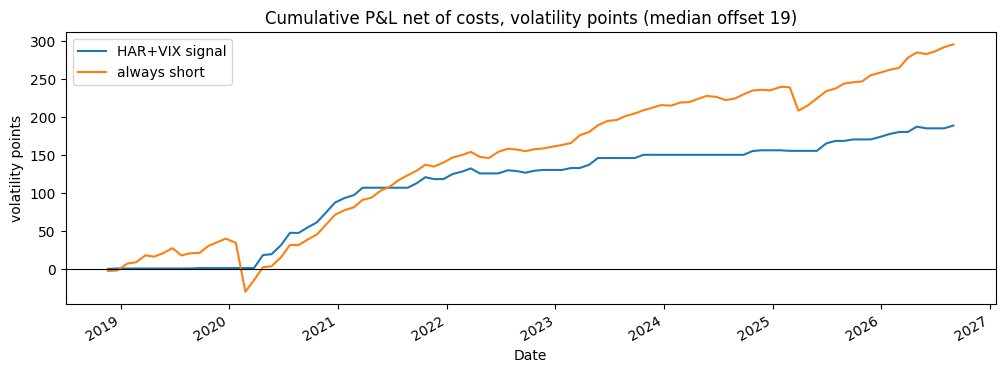

In [ ]:
b   = backtest(sig, "spread", thresh)
off = int(b["sharpe"].sub(b["sharpe"].median()).abs().idxmin())

t   = sig.iloc[off::HOLD]
on  = (t["spread"] > thresh).astype(int)
pnl = pd.DataFrame({"HAR+VIX signal": on * t["premium"] - on * COST,
                    "always short":   t["premium"] - COST})

pnl.cumsum().plot(figsize=(12, 4),
    title=f"Cumulative P&L net of costs, volatility points (median offset {off})")
plt.axhline(0, lw=0.8, color="k"); plt.ylabel("volatility points"); plt.show()

---

## Summary

| | |
| --- | --- |
| **Forecasting hypothesis** | Rejected. HAR adds 0.007 of R² over a rescaled VIX; `rv_m` loses all significance once VIX enters. |
| **Economic hypothesis** | Confirmed. Debiasing VIX lifts R² from 0.178 to 0.312; the premium averages 2–3 volatility points. |
| **Strategy hypothesis** | Confirmed, decisively. Sharpe 1.49 against 0.97 for a VIX level rule and 1.32 for always-short; worst month −28 against −56. |
| **Main limitation** | ~95 independent observations. The difference between high- and low-spread months is only t ≈ 1.9. |

**Do not sell volatility on the VIX level. Sell it on VIX relative to recent realised volatility.**

In [ ]:
import shutil
shutil.make_archive("data", "zip", "data")

from google.colab import files      # drop these two lines if you're not in Colab
files.download("data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
r = ladder  # or any single offset's pnl series
sr = r.mean()/r.std()
se = np.sqrt((1 + sr**2/2 - r.skew()*sr + r.kurtosis()/4*sr**2)/len(r))*np.sqrt(12)
print(f"corrected SE(Sharpe) = {se:.2f}")

NameError: name 'ladder' is not defined